# BD532 Lab 3.1 (Colab): ทำนายราคาปิดหุ้น S&P 500 ล่วงหน้า 7 วันทำการด้วย Deep Learning

โน้ตบุ๊กนี้คือ **ฝั่ง training** ของ Lab 3 เทรน **LSTM** และ **Transformer แบบ PatchTST** ด้วย PyTorch เทียบกับ baseline แล้ว export โมเดลที่ดีที่สุดเป็นไฟล์ **ONNX** ใน `bd532_stock_artifacts.zip` เพื่อนำไป deploy เป็นงานตั้งเวลาก่อนตลาดเปิดใน **Lab 3.2** (คู่มือ `BD532-Lab3-Stock-Forecast.md`)

| ส่วน | นาทีที่ | เนื้อหา | ผลลัพธ์ |
|---|---|---|---|
| 0 | 0 | ติดตั้ง library, เลือก GPU | พร้อมทำงาน |
| 1–3 | 5 | `stock_pipeline.py`, ดาวน์โหลดและตรวจข้อมูล, feature, target และ **หน้าต่างลำดับเวลา 60 วัน** | `X` shape (N, 60, 9) |
| 4–5 | 15 | random split vs time split (leakage), แบ่ง train/valid/test ตามเวลา | ชุดข้อมูลที่ไม่รั่ว |
| 6 | 25 | baseline: naive และ Gradient Boosting (ตาราง) | เส้นที่ deep learning ต้องเอาชนะ |
| 7 | 30 | **LSTM vs Transformer**: quantile loss, early stopping, learning curve | ตารางเทียบ 4 โมเดล |
| 8 | 55 | เลือกโมเดล, conformal calibration, ทดสอบบน test ครั้งเดียว | ตาราง test + coverage |
| 9–10 | 65 | เทรนครั้งสุดท้าย, export ONNX + ตรวจผลตรงกับ PyTorch, export artifacts | `bd532_stock_artifacts.zip` |

> ⚠️ **Lab นี้สอนการสร้างระบบ ML สำหรับข้อมูลอนุกรมเวลา ไม่ใช่คำแนะนำการลงทุน** ราคาหุ้นรายวันใกล้เคียง random walk มาก **deep learning ไม่ได้ทำให้ทำนายตลาดได้** โมเดลที่ดีที่สุดในโน้ตบุ๊กนี้จะชนะการเดาว่า "ราคาพรุ่งนี้เท่ากับวันนี้" ได้น้อยมากหรือไม่ชนะเลย คำถามที่ Lab ให้ตอบคือ **ความซับซ้อนที่เพิ่มขึ้นแลกกับอะไรบ้าง**

**สิ่งที่ฝึกใน Lab นี้**

1. **Data leakage แบบอนุกรมเวลา:** แบ่งข้อมูลแบบสุ่มไม่ได้ ต้องแบ่งตามเวลาและเว้นช่วง (purge)
2. **Baseline ก่อนโมเดล:** วัด deep learning เทียบกับ naive และโมเดลตาราง (Gradient Boosting) เสมอ
3. **Sequence model:** LSTM อ่านข้อมูลทีละวัน, Transformer มองหน้าต่างทั้งหมดพร้อมกันด้วย attention
4. **Multi-horizon + quantile output:** โมเดลเดียวทำนายทั้ง 7 วัน และทำนายขอบล่าง/ค่ากลาง/ขอบบนของช่วง 80% ในตัว (quantile/pinball loss)
5. **Conformal calibration:** ปรับช่วงคาดการณ์ให้ครอบคลุมจริงตามที่สัญญา
6. **Export เป็น ONNX:** ฝั่ง deploy ไม่ต้องติดตั้ง PyTorch ใช้ `onnxruntime` ซึ่งเล็กกว่ามาก และตรวจว่าผลตรงกับ PyTorch

## ส่วน 0: เตรียมเครื่อง (5 นาที)

1. แนะนำ **Runtime → Change runtime type → T4 GPU** (เทรนสองโมเดลประมาณ 3–5 นาที) ถ้าไม่ได้ GPU ใช้ CPU ได้ แต่ส่วน 7 จะใช้เวลาประมาณ 15–25 นาที
2. รันเซลล์ทีละเซลล์ด้วย `Shift + Enter`

In [28]:
# yfinance ต้องเป็นเวอร์ชันล่าสุด เพราะ Yahoo เปลี่ยนระบบบ่อย · onnx/onnxscript ใช้ export, onnxruntime ใช้ทดสอบไฟล์ที่ export
%pip install -q -U yfinance pandas_market_calendars onnx onnxscript onnxruntime

In [29]:
import datetime, json, math, os, shutil, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, onnx, onnxruntime, yfinance as yf, pandas_market_calendars as mcal

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} ({DEV}) | onnxruntime {onnxruntime.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__} | yfinance {yf.__version__}")

# ---------- ค่าตั้งต้นของ Lab (ทุกค่าจะถูกบันทึกลง model_metadata.json) ----------
TICKERS = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "JPM", "XOM", "JNJ", "WMT", "KO"]   # หุ้นใน S&P 500 หลาย sector
START = "2015-01-01"
VALID_DAYS = 250       # ~1 ปีทำการ
TEST_DAYS = 250        # ~1 ปีทำการ (ล่าสุด)
SAMPLE_DAYS = 120      # ข้อมูลตัวอย่างที่ส่งไปตรวจงานตั้งเวลา (ต้อง ≥ MIN_HISTORY ใน stock_pipeline)
LEVEL = 0.8            # ช่วงคาดการณ์ 80% (quantile 0.1 และ 0.9)
MAX_EPOCHS, PATIENCE, BATCH, LR, SEED = 25, 5, 256, 1e-3, 42

python 3.13.16 | torch 2.14.1+cu130 (cuda) | onnxruntime 1.32.0 | pandas 3.1.1 | numpy 2.4.6 | yfinance 1.8.0


> ✅ **Checkpoint 0**: เห็นเวอร์ชันของ library ครบ และ `(cuda)` ถ้าเลือก GPU (จดเวอร์ชัน `python`, `numpy`, `pandas` ไว้ จะต้องใช้เวอร์ชันเดียวกันตอน deploy)

### โจทย์: "ล่วงหน้า 7 วัน" หมายถึงอะไรกันแน่

| คำถาม | นิยามใน Lab นี้ |
|---|---|
| 7 วัน นับอย่างไร | **7 วันทำการของตลาด NYSE** (ข้ามเสาร์-อาทิตย์และวันหยุดตลาด) ไม่ใช่ 7 วันตามปฏิทิน |
| ทำนายเมื่อไร | ทุกเช้าวันทำการ **07:20 เวลานิวยอร์ก** ก่อนตลาดเปิด 09:30 (= 19:20 เวลาไทยช่วง พ.ย.–มี.ค. และ 18:20 ช่วง มี.ค.–พ.ย.) |
| ใช้ข้อมูลถึงวันไหน | ราคาปิดของวันทำการล่าสุดที่ปิดตลาดแล้ว เรียกว่า `as_of` |
| โมเดลเห็นอะไร | ค่ารายวัน 9 ช่อง ของ **60 วันทำการล่าสุด** (หน้าต่างลำดับเวลา) |
| ทำนายค่าอะไร | `z_h = log(Close[t+h] / Close[t]) / (vol_20 × √h)` คือผลตอบแทนในหน่วย "กี่เท่าของความผันผวนปกติ" แล้วแปลงกลับเป็นราคา |
| output | **โมเดลเดียว** ให้ค่า 7 horizon × 3 quantile (0.1, 0.5, 0.9) = 21 ตัวเลขต่อหุ้น (multi-horizon, MIMO) |

```text
 ศุกร์ 16:00 ET         จันทร์ 07:20 ET              จันทร์ 09:30 ET → 16:00 ET          …  พุธถัดไป 16:00 ET
 ตลาดปิด ─────────────▶ GitHub Actions รัน ─────────▶ ตลาดเปิด → ปิด ───────────────▶ … ─▶ ปิด
 Close ล่าสุด = as_of     ทำนาย h = 1 … 7              ราคาจริงของ h = 1                     ราคาจริงของ h = 7
```

**คำถามชวนคิด:** ทำไมทำนาย log return หารด้วย `vol_20 × √h` แทนราคาโดยตรง

<details><summary>เฉลย</summary>

1. ราคาแต่ละหุ้นต่างระดับกันมาก (KO ~70 ดอลลาร์, MSFT ~400 ดอลลาร์) และเลื่อนขึ้นตลอดเวลา (non-stationary) โมเดลที่เทรนกับราคาจะเจอค่าในอนาคตที่ไม่เคยเห็น ส่วน log return อยู่ใกล้ 0 ทุกหุ้นทุกช่วงเวลา จึงใช้โมเดลเดียวกับหลายหุ้นได้ (global model)
2. หุ้นผันผวนสูง (NVDA) แกว่งวันละหลาย % หุ้นผันผวนต่ำ (KO) แกว่งไม่ถึง 1% ถ้าไม่หาร loss จะถูกครอบงำโดยหุ้นผันผวนสูงและช่วงวิกฤต การหารด้วย `vol_20` ทำให้ target ทุกหุ้นอยู่ในสเกลใกล้กัน และ `√h` ทำให้ทุก horizon อยู่ในสเกลเดียวกัน (ความแปรปรวนของผลรวม h วันโตตาม h) neural network เทรนง่ายขึ้นมากเมื่อ target มีสเกลใกล้ 1
</details>

## ส่วน 1: โค้ดที่ใช้ร่วมกันระหว่าง training และ serving (`stock_pipeline.py`)

เหมือน `leaf_noise.py` ใน Lab 2.1 โค้ดดาวน์โหลด ตรวจข้อมูล สร้าง feature สร้างหน้าต่าง normalize และแปลงผลเป็นราคา ต้อง **เป็นไฟล์เดียวกัน** ทั้งตอนเทรนและตอนรันจริง ไฟล์นี้ **ไม่ import PyTorch** โมเดลถูกส่งเข้า `forecast()` เป็นฟังก์ชัน ตอนเทรนใช้ PyTorch ตอนรันจริงใช้ไฟล์ ONNX

จุดที่ควรอ่าน: `download_prices()` (`auto_adjust=False`), `drop_incomplete_bar()`, `validate_prices()`, `SEQ_FEATURES`, `make_windows()`, `latest_windows()`, `normalize()`, `target_scale()`, `forecast()`

In [30]:
%%writefile stock_pipeline.py
"""stock_pipeline.py — โค้ดที่ใช้ร่วมกันทั้งตอนเทรน (Colab, Lab 3.1) และตอนทำนายจริง (GitHub Actions, Lab 3.2)

ไฟล์นี้คือ "สัญญา" ระหว่าง training กับ serving: ดาวน์โหลดข้อมูล, ตรวจข้อมูล, สร้าง feature, สร้างหน้าต่างลำดับเวลา
(sequence window) ให้โมเดล deep learning, normalize และแปลงผลทำนายเป็นราคา
ถ้าแก้ไฟล์นี้ ต้องเทรนใหม่และ export ใหม่ทั้งชุด (check_artifacts.py จะจับได้ถ้าแก้ฝั่งเดียว)

ไฟล์นี้ไม่ import PyTorch: โมเดลถูกส่งเข้ามาเป็นฟังก์ชัน predict_fn(X) -> quantiles
ตอนเทรนใช้โมเดล PyTorch ตอนรันจริงใช้ไฟล์ ONNX ผ่าน onnxruntime (ติดตั้งเล็กกว่า PyTorch หลายสิบเท่า)

ทุก feature ใช้หน้าต่างย้อนหลังจำกัด จึงคำนวณจากข้อมูลย้อนหลังไม่กี่เดือนได้ค่าเท่ากับตอนเทรนที่ใช้ข้อมูลสิบปีทุกประการ
"""
from __future__ import annotations

import time
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd

FEATURE_VERSION = "v2-seq"
MARKET = "^GSPC"                     # ดัชนี S&P 500 ใช้เป็น feature ภาวะตลาด
HORIZONS = list(range(1, 8))         # ทำนายราคาปิดล่วงหน้า 1–7 วันทำการ
QUANTILES = [0.1, 0.5, 0.9]          # โมเดลทำนาย 3 quantile: ขอบล่าง, ค่ากลาง (median), ขอบบนของช่วง 80%
MAX_WINDOW = 60                      # หน้าต่างย้อนหลังที่ยาวที่สุดที่ feature ตาราง (FEATURES) ใช้
SEQ_LEN = 60                         # โมเดล deep learning เห็นข้อมูลย้อนหลัง 60 วันทำการต่อการทำนาย 1 ครั้ง
MIN_HISTORY = 100                    # วันขั้นต่ำต่อหุ้น: warm-up ของ feature 20 วัน + หน้าต่าง 60 วัน + เผื่อ
PRICE_COLS = ["Open", "High", "Low", "Close", "Volume"]
NY = ZoneInfo("America/New_York")

FEATURES = [
    "ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "ret_20",      # ผลตอบแทน (log) ย้อนหลัง k วัน
    "vol_5", "vol_20",                                          # ความผันผวน
    "sma_ratio_5", "sma_ratio_20", "sma_ratio_50",              # ราคาเทียบเส้นค่าเฉลี่ย
    "dist_high_60", "rsi_14", "hl_range", "volume_z_20",
    "mkt_ret_1", "mkt_ret_5", "mkt_ret_20", "mkt_vol_20", "rel_ret_20",
    "dow",                                                      # วันในสัปดาห์ 0=จันทร์
]

# input ของโมเดล deep learning: ค่ารายวัน 9 ช่องต่อวัน × 60 วัน (ใช้หน้าต่างย้อนหลังไม่เกิน 20 วัน)
# ไม่ใส่ ret_2…ret_20 หรือ sma_ratio_50 เพราะโมเดลลำดับเวลาเห็นวันก่อนหน้าทั้ง 60 วันอยู่แล้ว เรียนรู้เองได้
SEQ_FEATURES = ["ret_1", "hl_range", "volume_z_20", "vol_20", "sma_ratio_20", "rsi_14",
                "mkt_ret_1", "mkt_vol_20", "rel_ret_20"]


# ---------------------------------------------------------------- ดาวน์โหลดข้อมูล
def download_prices(tickers, start, end=None, retries=3, pause=10.0) -> pd.DataFrame:
    """ดาวน์โหลดราคารายวันจาก Yahoo Finance แล้วคืนเป็นตารางแบบ long: Date, Ticker, Open, High, Low, Close, Volume

    ใช้ auto_adjust=False: Close คือราคาปิดที่ซื้อขายจริง (Yahoo ปรับเฉพาะ stock split ให้แล้ว)
    yf.download() ไม่ raise error เมื่อดาวน์โหลดไม่สำเร็จ แต่คืนตารางว่างหรือคอลัมน์ที่เป็น NaN จึงต้อง validate_prices() ต่อเสมอ
    """
    import yfinance as yf

    symbols = list(dict.fromkeys([*tickers, MARKET]))
    raw = None
    for attempt in range(1, retries + 1):
        try:
            raw = yf.download(symbols, start=start, end=end, interval="1d", auto_adjust=False,
                              actions=False, progress=False, threads=False, group_by="column",
                              multi_level_index=True)
        except Exception as e:                       # เช่น YFRateLimitError
            print(f"  download attempt {attempt}: {type(e).__name__}: {e}")
            raw = None
        if raw is not None and not raw.empty:
            break
        if attempt < retries:
            time.sleep(pause * attempt)              # รอนานขึ้นทุกครั้ง (backoff)
    if raw is None or raw.empty:
        raise RuntimeError("ดาวน์โหลดข้อมูลจาก Yahoo Finance ไม่สำเร็จ (ตารางว่าง)")
    return to_long(raw)


def to_long(raw: pd.DataFrame) -> pd.DataFrame:
    """แปลงผลของ yf.download (คอลัมน์ 2 ชั้น: Price × Ticker) เป็นตาราง long"""
    frames = []
    for t in raw.columns.get_level_values(1).unique():
        df = raw.xs(t, axis=1, level=1)[PRICE_COLS].dropna(subset=["Close"]).copy()
        df["Ticker"] = t
        frames.append(df)
    out = pd.concat(frames)
    out.index.name = "Date"
    out.columns.name = None
    out = out.reset_index()
    d = pd.to_datetime(out["Date"])
    if d.dt.tz is not None:
        d = d.dt.tz_localize(None)
    out["Date"] = d.dt.normalize()
    return out[["Date", "Ticker", *PRICE_COLS]].sort_values(["Ticker", "Date"]).reset_index(drop=True)


def drop_incomplete_bar(prices: pd.DataFrame, now_utc: pd.Timestamp, close_buffer_min: int = 30) -> pd.DataFrame:
    """ตัดแท่งของ "วันนี้" ทิ้งถ้าตลาดยังปิดไม่เสร็จ

    ถ้ารันระหว่างตลาดเปิด Yahoo จะส่งแท่งของวันนี้มาด้วย โดย Close คือราคาล่าสุด ณ ขณะนั้น (ยังไม่ใช่ราคาปิด)
    ถ้าไม่ตัดทิ้ง โมเดลจะทำนายจากราคาที่ยังไม่จบวัน
    """
    now_ny = pd.Timestamp(now_utc).tz_convert(NY)
    today = pd.Timestamp(now_ny.date())
    closed = now_ny.hour * 60 + now_ny.minute >= 16 * 60 + close_buffer_min
    if closed:
        return prices
    return prices[prices["Date"] < today].reset_index(drop=True)


# ---------------------------------------------------------------- ตรวจคุณภาพข้อมูล
def validate_prices(prices: pd.DataFrame, tickers, now_utc=None, max_age_days: int = 5):
    """คืน (errors, warnings) — มี error แปลว่าห้ามนำข้อมูลนี้ไปทำนาย"""
    errors, warnings = [], []
    if prices is None or prices.empty:
        return ["ไม่มีข้อมูลราคาเลย"], warnings
    need = list(dict.fromkeys([*tickers, MARKET]))
    counts = prices.groupby("Ticker").size()
    for t in need:
        n = int(counts.get(t, 0))
        if n < MIN_HISTORY:
            errors.append(f"{t}: มีข้อมูล {n} วัน น้อยกว่าขั้นต่ำ {MIN_HISTORY} วัน")
    if prices.duplicated(["Ticker", "Date"]).any():
        errors.append("มีแถวซ้ำ (Ticker, Date)")
    if prices["Close"].isna().any() or (prices["Close"] <= 0).any():
        errors.append("มีราคาปิดว่างหรือไม่เป็นบวก")
    if (prices["High"] < prices["Low"]).any():
        errors.append("มีแถวที่ High < Low")
    last = prices[prices["Ticker"].isin(need)].groupby("Ticker")["Date"].max()
    if last.nunique() > 1:
        errors.append(f"วันที่ล่าสุดของแต่ละหุ้นไม่ตรงกัน: {last.astype(str).to_dict()}")
    if now_utc is not None and len(last):
        age = (pd.Timestamp(now_utc).tz_convert(NY).tz_localize(None).normalize() - last.max()).days
        if age > max_age_days:
            errors.append(f"ข้อมูลล่าสุดคือ {last.max().date()} เก่าเกิน {max_age_days} วัน (ตลาดหยุดยาวหรือดาวน์โหลดไม่ได้)")
    lr = np.log(prices["Close"]).groupby(prices["Ticker"]).diff().abs()
    jumps = prices.loc[lr > 0.4, ["Ticker", "Date"]]
    if len(jumps):
        warnings.append(f"ราคาเปลี่ยนเกิน ±40% ในวันเดียว {len(jumps)} ครั้ง (split ที่ยังไม่ถูกปรับ?): "
                        f"{jumps.head(3).astype(str).values.tolist()}")
    return errors, warnings


# ---------------------------------------------------------------- feature
def _rsi(close: pd.Series, n: int = 14) -> pd.Series:
    # ใช้ค่าเฉลี่ยแบบหน้าต่างคงที่ (ไม่ใช้ ewm) เพื่อให้ค่าไม่ขึ้นกับว่าดาวน์โหลดข้อมูลย้อนหลังมาเท่าไร
    d = close.diff()
    up = d.clip(lower=0).rolling(n).mean()
    down = (-d.clip(upper=0)).rolling(n).mean()
    return 100 - 100 / (1 + up / down.replace(0, np.nan))


def _one_ticker(g: pd.DataFrame) -> pd.DataFrame:
    c = g["Close"]
    lr = np.log(c).diff()
    f = pd.DataFrame(index=g.index)
    for k in (1, 2, 3, 5, 10, 20):
        f[f"ret_{k}"] = np.log(c / c.shift(k))
    f["vol_5"] = lr.rolling(5).std()
    f["vol_20"] = lr.rolling(20).std()
    for k in (5, 20, 50):
        f[f"sma_ratio_{k}"] = c / c.rolling(k).mean() - 1
    f["dist_high_60"] = c / c.rolling(MAX_WINDOW).max() - 1
    f["rsi_14"] = _rsi(c, 14) / 100
    f["hl_range"] = np.log(g["High"] / g["Low"])
    lv = np.log1p(g["Volume"].astype(float))
    f["volume_z_20"] = (lv - lv.rolling(20).mean()) / lv.rolling(20).std()
    return f


def build_features(prices: pd.DataFrame) -> pd.DataFrame:
    """คืนตาราง Date, Ticker, Close + FEATURES (แถวที่ข้อมูลย้อนหลังยังไม่พอจะมี NaN)"""
    p = prices.sort_values(["Ticker", "Date"]).reset_index(drop=True)
    feats = pd.concat([_one_ticker(g) for _, g in p.groupby("Ticker", sort=False)])
    out = pd.concat([p[["Date", "Ticker", "Close"]], feats.loc[p.index]], axis=1)

    m = p[p["Ticker"] == MARKET].set_index("Date")["Close"]
    mlr = np.log(m).diff()
    mkt = pd.DataFrame({
        "mkt_ret_1": np.log(m / m.shift(1)),
        "mkt_ret_5": np.log(m / m.shift(5)),
        "mkt_ret_20": np.log(m / m.shift(20)),
        "mkt_vol_20": mlr.rolling(20).std(),
    })
    out = out[out["Ticker"] != MARKET].merge(mkt, left_on="Date", right_index=True, how="left")
    out["rel_ret_20"] = out["ret_20"] - out["mkt_ret_20"]
    out["dow"] = out["Date"].dt.dayofweek
    return out[["Date", "Ticker", "Close", *FEATURES]].reset_index(drop=True)


def add_targets(feat: pd.DataFrame) -> pd.DataFrame:
    """เพิ่มเป้าหมาย y_h = log(Close[t+h] / Close[t]) สำหรับ h = 1..7 (ใช้ตอนเทรนเท่านั้น)"""
    out = feat.sort_values(["Ticker", "Date"]).copy()
    g = out.groupby("Ticker")["Close"]
    for h in HORIZONS:
        out[f"y_{h}"] = np.log(g.shift(-h) / out["Close"])
    return out


# ---------------------------------------------------------------- หน้าต่างลำดับเวลา (sequence window)
def make_windows(feat: pd.DataFrame):
    """สร้างหน้าต่างย้อนหลังทุกวันของทุกหุ้น (ใช้ตอนเทรน)

    คืน X shape (N, SEQ_LEN, len(SEQ_FEATURES)) — X[i] คือ SEQ_FEATURES ของวัน t−59 … t
    และ idx: แถวของวัน t (มี Date, Ticker, Close, vol_20 และ y_h ถ้ามี) เรียงตรงกับ X
    """
    Xs, idxs = [], []
    for _, g in feat.sort_values(["Ticker", "Date"]).groupby("Ticker", sort=False):
        a = g[SEQ_FEATURES].to_numpy(np.float32)
        if len(a) < SEQ_LEN:
            continue
        w = np.lib.stride_tricks.sliding_window_view(a, SEQ_LEN, axis=0).transpose(0, 2, 1)
        ok = ~np.isnan(w).any(axis=(1, 2))
        Xs.append(w[ok])
        idxs.append(g.iloc[SEQ_LEN - 1:][ok])
    return np.ascontiguousarray(np.concatenate(Xs)), pd.concat(idxs).reset_index(drop=True)


def latest_windows(feat: pd.DataFrame, tickers):
    """หน้าต่างล่าสุด 1 อันต่อหุ้น (ใช้ตอนทำนายจริง) — ทุกหุ้นต้องจบที่วันเดียวกันและไม่มีค่าว่าง"""
    X, rows = [], []
    for t in tickers:
        g = feat[feat["Ticker"] == t].sort_values("Date").tail(SEQ_LEN)
        if len(g) < SEQ_LEN:
            raise ValueError(f"{t}: มีข้อมูลไม่ถึง {SEQ_LEN} วันสำหรับหน้าต่าง")
        if g[SEQ_FEATURES].isna().any().any():
            raise ValueError(f"{t}: หน้าต่างล่าสุดมีค่าว่าง (ข้อมูลย้อนหลังไม่พอหรือมีวันหาย)")
        X.append(g[SEQ_FEATURES].to_numpy(np.float32))
        rows.append(g.iloc[-1])
    idx = pd.DataFrame(rows).reset_index(drop=True)
    if idx["Date"].nunique() != 1:
        raise ValueError(f"วันที่ล่าสุดของแต่ละหุ้นไม่ตรงกัน: {idx.set_index('Ticker')['Date'].astype(str).to_dict()}")
    return np.stack(X), idx


def normalize(X: np.ndarray, meta: dict) -> np.ndarray:
    """standardize ด้วย mean/std ที่คำนวณจากชุด train (เก็บใน meta) แล้วตัดค่าสุดโต่งที่ ±5"""
    mean = np.asarray(meta["scaler"]["mean"], np.float32)
    std = np.asarray(meta["scaler"]["std"], np.float32)
    return np.clip((X - mean) / std, -5, 5).astype(np.float32)


def target_scale(idx: pd.DataFrame) -> np.ndarray:
    """ตัวหารของ target: vol_20 × √h — โมเดลทำนายผลตอบแทนในหน่วย "กี่เท่าของความผันผวนปกติ" shape (N, 7)"""
    return idx["vol_20"].to_numpy()[:, None] * np.sqrt(np.asarray(HORIZONS, float))[None, :]


# ---------------------------------------------------------------- ทำนาย
def onnx_predictor(path):
    """โหลดโมเดล ONNX แล้วคืนฟังก์ชัน predict_fn(X) -> (N, 7, 3)"""
    import onnxruntime as ort
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1          # 1 thread: ลำดับการบวกเลขทศนิยมคงที่ ผลจึงตรงกันทุกเครื่อง
    sess = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
    return lambda X: sess.run(None, {"x": np.ascontiguousarray(X, np.float32)})[0]


def forecast(predict_fn, meta: dict, X: np.ndarray, idx: pd.DataFrame) -> pd.DataFrame:
    """ทำนายราคาปิด h = 1..7 พร้อมช่วงคาดการณ์ 80%

    predict_fn(X normalized) คืน quantile ของ z = log return / (vol_20 × √h) shape (N, 7, 3)
    ช่วงคาดการณ์ขยาย/หดด้วยค่า conformal (meta["interval"]["cqr"]) ที่ปรับจากชุด validation
    """
    q = np.asarray(predict_fn(normalize(X, meta)), dtype=np.float64)
    adj = np.array([meta["interval"]["cqr"][str(h)] for h in HORIZONS])
    scale = target_scale(idx)
    mid = q[..., 1] * scale
    lo = np.minimum((q[..., 0] - adj) * scale, mid)
    hi = np.maximum((q[..., 2] + adj) * scale, mid)
    rows = []
    for i, t in enumerate(idx["Ticker"]):
        c = float(idx["Close"].iloc[i])
        for j, h in enumerate(HORIZONS):
            rows.append({"ticker": t, "h": h, "last_close": c, "pred_logret": float(mid[i, j]),
                         "pred_close": c * float(np.exp(mid[i, j])),
                         "lo": c * float(np.exp(lo[i, j])), "hi": c * float(np.exp(hi[i, j]))})
    return pd.DataFrame(rows)


def next_sessions(after: pd.Timestamp, n: int = 7) -> list[pd.Timestamp]:
    """วันทำการถัดไป n วันของตลาด NYSE หลังวันที่ after (ข้ามวันหยุดตลาด)"""
    after = pd.Timestamp(after).normalize()
    try:
        import pandas_market_calendars as mcal
        days = mcal.get_calendar("XNYS").valid_days(after + pd.Timedelta(days=1), after + pd.Timedelta(days=30))
        days = [pd.Timestamp(d).tz_localize(None).normalize() for d in days]
    except ImportError:                                       # สำรอง: จันทร์–ศุกร์ (ไม่รู้จักวันหยุดตลาด)
        days = list(pd.bdate_range(after + pd.Timedelta(days=1), periods=n))
    return days[:n]

Overwriting stock_pipeline.py


In [31]:
import importlib
import stock_pipeline as sp
importlib.reload(sp)                     # ถ้าแก้ไฟล์แล้วรันเซลล์ %%writefile ใหม่ ให้รันเซลล์นี้ด้วย
print("feature version:", sp.FEATURE_VERSION, "| SEQ_LEN:", sp.SEQ_LEN, "| SEQ_FEATURES:", sp.SEQ_FEATURES)

feature version: v2-seq | SEQ_LEN: 60 | SEQ_FEATURES: ['ret_1', 'hl_range', 'volume_z_20', 'vol_20', 'sma_ratio_20', 'rsi_14', 'mkt_ret_1', 'mkt_vol_20', 'rel_ret_20']


## ส่วน 2: ดาวน์โหลดและตรวจข้อมูล

ดาวน์โหลดราคารายวันของ 10 หุ้น + ดัชนี S&P 500 (`^GSPC`) ตั้งแต่ปี 2015 จาก Yahoo Finance

In [32]:
NOW = pd.Timestamp.now(tz="UTC")
prices = sp.download_prices(TICKERS, START)
prices = sp.drop_incomplete_bar(prices, NOW)        # ถ้ารันระหว่างตลาดเปิด แท่งของวันนี้ยังไม่ใช่ราคาปิด
errors, warns = sp.validate_prices(prices, TICKERS, now_utc=NOW)
print("errors:", errors or "ไม่มี")
print("warnings:", warns or "ไม่มี")
assert not errors, "ข้อมูลไม่ผ่านการตรวจ ห้ามเทรนต่อ"

prices.groupby("Ticker").agg(first=("Date", "min"), last=("Date", "max"), days=("Date", "size"),
                             last_close=("Close", "last"))

errors: ไม่มี
warnings: ไม่มี


,first,last,days,last_close
Ticker,,,,
AAPL,2015-01-02,2026-11-13,2985,356.269989
AMZN,2015-01-02,2026-11-13,2985,266.660004
GOOGL,2015-01-02,2026-11-13,2985,295.769989
JNJ,2015-01-02,2026-11-13,2985,285.750000
JPM,2015-01-02,2026-11-13,2985,346.190002
KO,2015-01-02,2026-11-13,2985,99.250000
MSFT,2015-01-02,2026-11-13,2985,523.880005
NVDA,2015-01-02,2026-11-13,2985,162.850006
WMT,2015-01-02,2026-11-13,2985,128.089996


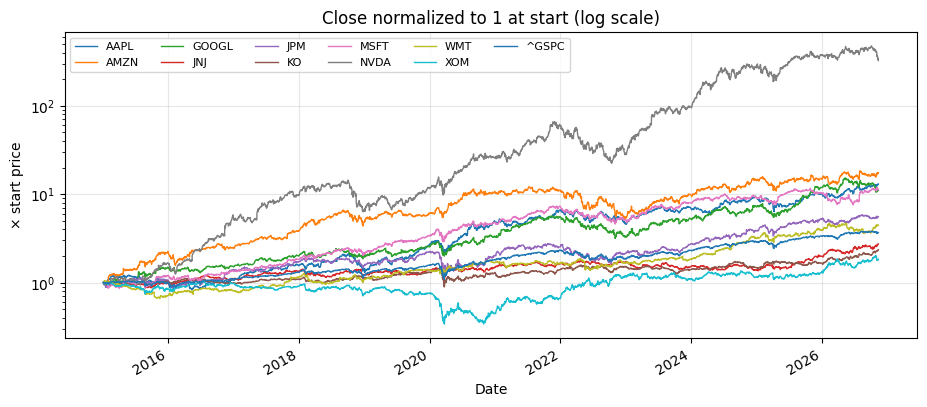

In [33]:
wide = prices.pivot(index="Date", columns="Ticker", values="Close")
ax = (wide / wide.iloc[0]).plot(figsize=(11, 4.5), logy=True, lw=1)
ax.set_title("Close normalized to 1 at start (log scale)"); ax.set_ylabel("× start price"); ax.grid(alpha=.3)
ax.legend(ncol=6, fontsize=8); plt.show()

**ทำไม `auto_adjust=False`:** ค่าเริ่มต้นของ `yf.download()` เวอร์ชันใหม่คือ `auto_adjust=True` ซึ่งปรับราคาย้อนหลังด้วยเงินปันผล ราคาในอดีตจึงไม่ตรงกับราคาที่ซื้อขายจริงและ **เปลี่ยนทุกครั้งที่มีการจ่ายปันผล** ระบบนี้ทำนายราคาปิดที่คนเห็นในตลาดและต้องเทียบกับราคาจริงในอนาคต จึงใช้ `Close` ที่ปรับเฉพาะ stock split (ถ้าไม่ปรับ split หุ้น NVDA ที่แตกพาร์ 10:1 ในปี 2024 จะดูเหมือนราคาร่วง 90% ในวันเดียว)

**ข้อมูลเสียแบบเงียบ:** `yf.download()` **ไม่ raise error** เมื่อดาวน์โหลดไม่สำเร็จ แต่คืนตารางว่างหรือคอลัมน์ NaN ถ้าไม่มี `validate_prices()` ระบบจะทำนายจากข้อมูลเสียต่อไปโดยไม่มีใครรู้

In [34]:
cases = {
    "ตารางว่าง (ดาวน์โหลดไม่ได้)": prices.iloc[0:0],
    "หุ้น 1 ตัวหายไป": prices[prices.Ticker != "KO"],
    "ข้อมูลเก่า (ระบบรันเมื่อหยุดยาว 10 วัน)": prices,
    "มีแถวซ้ำ": pd.concat([prices, prices.tail(1)]),
}
for name, df in cases.items():
    now = NOW + pd.Timedelta(days=10) if "เก่า" in name else NOW
    err, _ = sp.validate_prices(df, TICKERS, now_utc=now)
    print(f"{name:<38} → {err[:1]}")

ตารางว่าง (ดาวน์โหลดไม่ได้)            → ['ไม่มีข้อมูลราคาเลย']
หุ้น 1 ตัวหายไป                        → ['KO: มีข้อมูล 0 วัน น้อยกว่าขั้นต่ำ 100 วัน']
ข้อมูลเก่า (ระบบรันเมื่อหยุดยาว 10 วัน) → ['ข้อมูลล่าสุดคือ 2026-11-13 เก่าเกิน 5 วัน (ตลาดหยุดยาวหรือดาวน์โหลดไม่ได้)']
มีแถวซ้ำ                               → ['มีแถวซ้ำ (Ticker, Date)']


## ส่วน 3: Feature, target และหน้าต่างลำดับเวลา

**ข้อมูลสองรูปแบบ** สำหรับโมเดลสองตระกูล

| รูปแบบ | ใช้กับ | หน้าตา |
|---|---|---|
| ตาราง (`FEATURES` 21 คอลัมน์) | Gradient Boosting (baseline) | 1 แถว = 1 วัน ต้องสร้าง feature ย้อนหลังเอง (`ret_5`, `ret_20`, `sma_ratio_50` …) |
| หน้าต่าง (`SEQ_FEATURES` 9 ช่อง × 60 วัน) | LSTM, Transformer | 1 ตัวอย่าง = ตาราง 60 × 9 ของ 60 วันล่าสุด โมเดลเรียนรู้รูปแบบตามเวลาเอง |

`SEQ_FEATURES`: `ret_1` (ผลตอบแทนรายวัน), `hl_range` (ช่วงราคาสูง-ต่ำ), `volume_z_20`, `vol_20`, `sma_ratio_20`, `rsi_14`, `mkt_ret_1`, `mkt_vol_20`, `rel_ret_20` ทุกตัวของวัน `t` ใช้ข้อมูล **ถึงวัน `t` เท่านั้น** ส่วน target `y_h` ใช้ราคาของวัน `t+h` (`shift(-h)`) ซึ่งมีเฉพาะตอนเทรน

In [35]:
feat = sp.build_features(prices)
data = sp.add_targets(feat)
Y = [f"y_{h}" for h in sp.HORIZONS]

X_all, idx_all = sp.make_windows(data)                 # หน้าต่าง 60 วันของทุกวัน ทุกหุ้น
keep = (idx_all[Y].notna().all(axis=1) & idx_all[sp.FEATURES].notna().all(axis=1)).to_numpy()
X_lab, lab = X_all[keep], idx_all[keep].reset_index(drop=True)   # ตัวอย่างที่มีคำตอบครบ (ใช้เทรน/วัดผล)
print("X ทั้งหมด:", X_all.shape, "→ มี target ครบ:", X_lab.shape, "(ตัวอย่าง, วัน, ช่อง)")
print("ทุกโมเดลจะใช้ตัวอย่างชุดเดียวกัน", len(lab), "แถว (ตั้งแต่", lab.Date.min().date(), ")")
lab[lab.Ticker == "AAPL"][["Date", "Close", "ret_1", "vol_20", "rsi_14", "y_1", "y_7"]].tail(3)

X ทั้งหมด: (29060, 60, 9) → มี target ครบ: (28990, 60, 9) (ตัวอย่าง, วัน, ช่อง)
ทุกโมเดลจะใช้ตัวอย่างชุดเดียวกัน 28990 แถว (ตั้งแต่ 2015-04-28 )


,Date,Close,ret_1,vol_20,rsi_14,y_1,y_7
2896,2026-11-02,338.320007,-0.018479,0.010182,0.465880,-0.019159,0.049899
2897,2026-11-03,331.899994,-0.019159,0.011106,0.384696,0.051699,0.066946
2898,2026-11-04,349.510010,0.051699,0.016002,0.558118,-0.015396,0.019157


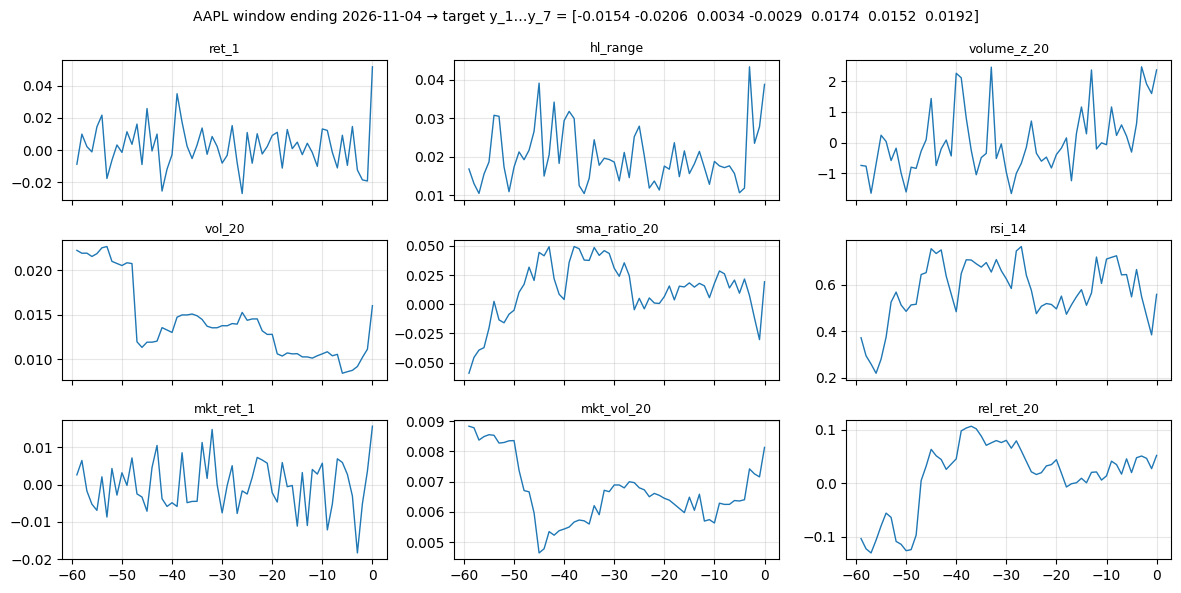

In [36]:
# ภาพของ 1 ตัวอย่าง: สิ่งที่โมเดล deep learning "เห็น" ก่อนทำนาย (AAPL วันล่าสุดที่มีคำตอบ)
i = lab.index[lab.Ticker == "AAPL"][-1]
fig, axes = plt.subplots(3, 3, figsize=(12, 6), sharex=True)
for ax, name, series in zip(axes.flat, sp.SEQ_FEATURES, X_lab[i].T):
    ax.plot(range(-sp.SEQ_LEN + 1, 1), series, lw=1); ax.set_title(name, fontsize=9); ax.grid(alpha=.3)
fig.suptitle(f"AAPL window ending {lab.Date[i].date()} → target y_1…y_7 = {np.round(lab.loc[i, Y].to_numpy(float), 4)}", fontsize=10)
plt.tight_layout(); plt.show()

**ทดสอบ: หน้าต่างล่าสุดคำนวณจากข้อมูลย้อนหลังสั้นๆ ได้ค่าเท่ากันหรือไม่** งานตั้งเวลาใน Lab 3.2 ดาวน์โหลดข้อมูลแค่ ~200 วัน ไม่ใช่ 10 ปี

In [37]:
recent = prices[prices.Date >= np.sort(prices.Date.unique())[-SAMPLE_DAYS]]
Xa, _ = sp.latest_windows(feat, TICKERS)
Xb, _ = sp.latest_windows(sp.build_features(recent), TICKERS)
print(f"ข้อมูล {prices.Date.nunique()} วัน vs {recent.Date.nunique()} วัน → หน้าต่าง {Xa.shape} ต่างกันมากที่สุด {np.abs(Xa - Xb).max():.2e}")

ข้อมูล 2985 วัน vs 120 วัน → หน้าต่าง (10, 60, 9) ต่างกันมากที่สุด 0.00e+00


**คำถามชวนคิด:** ถ้าเปลี่ยน RSI ไปใช้ค่าเฉลี่ยแบบ exponential (`ewm(alpha=1/14, adjust=False)`) ผลการทดสอบนี้จะเปลี่ยนอย่างไร

<details><summary>เฉลย</summary>

`ewm` มี "ความจำไม่สิ้นสุด" ค่าของวันนี้ขึ้นกับข้อมูลทุกวันตั้งแต่วันแรกที่ดาวน์โหลด ข้อมูล 10 ปีกับ 120 วันจะให้ค่าต่างกันเล็กน้อย เป็น training/serving skew ที่ไม่มี error แจ้ง วิธีแก้คือใช้หน้าต่างจำกัด (แบบในไฟล์นี้) หรือกำหนดให้ serving ดาวน์โหลดข้อมูลย้อนหลังยาวพอแล้วทดสอบว่าต่างไม่เกินเกณฑ์
</details>

## ส่วน 4: ทำไมแบ่งข้อมูลแบบสุ่มไม่ได้ (leakage ในอนุกรมเวลา)

ทดลองให้เห็นเร็วๆ ด้วย Gradient Boosting (เทรนไม่กี่วินาที) ทำนาย `y_7` สองแบบ แล้วเทียบกับ **naive forecast** (ทำนายว่าราคาไม่เปลี่ยน: `ŷ = 0`) ปัญหานี้เกิดกับ deep learning เหมือนกันทุกประการ

- **แบบ A — สุ่มแบ่ง (KFold shuffle):** วิธีที่ใช้ใน Lab 1.1
- **แบบ B — แบ่งตามเวลา:** เทรนด้วยอดีต ทดสอบด้วย 1 ปีล่าสุด

In [38]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict

def price_err(y_true, y_pred):
    # ความคลาดเคลื่อนของ "ราคา" เป็น % : |P̂ − P| / P = |exp(ŷ − y) − 1|
    return float(np.mean(np.abs(np.exp(np.asarray(y_pred) - np.asarray(y_true)) - 1)) * 100)

flex = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=20,
                                            early_stopping=False, random_state=42)
Xt_, y_ = lab[sp.FEATURES], lab["y_7"]
pred_a = cross_val_predict(flex(), Xt_, y_, cv=KFold(5, shuffle=True, random_state=0))
dates = np.sort(lab.Date.unique())
tr, te = lab.Date < dates[-TEST_DAYS - 7], lab.Date >= dates[-TEST_DAYS]
pred_b = flex().fit(Xt_[tr], y_[tr]).predict(Xt_[te])

leak = pd.DataFrame([
    {"วิธีแบ่ง": "A: สุ่ม (KFold shuffle)", "โมเดล %err": price_err(y_, pred_a), "naive %err": price_err(y_, 0 * y_)},
    {"วิธีแบ่ง": "B: ตามเวลา (1 ปีล่าสุด)", "โมเดล %err": price_err(y_[te], pred_b), "naive %err": price_err(y_[te], 0 * y_[te])},
]).round(3)
leak["โมเดลดีกว่า naive (%)"] = ((1 - leak["โมเดล %err"] / leak["naive %err"]) * 100).round(1)
leak

,วิธีแบ่ง,โมเดล %err,naive %err,โมเดลดีกว่า naive (%)
0,A: สุ่ม (KFold shuffle),3.009,3.282,8.3
1,B: ตามเวลา (1 ปีล่าสุด),3.696,3.596,-2.8


**อ่านผล:** แบบ A มักดูเหมือนโมเดล **ชนะ naive** ส่วนแบบ B (สถานการณ์จริง: ใช้อดีตทำนายอนาคต) มักชนะน้อยกว่ามากหรือแพ้ ถ้าเชื่อตัวเลขแบบ A เราจะ deploy โมเดลด้วยความคาดหวังที่ผิด

<details><summary>ทำไมแบบสุ่มถึงรั่ว</summary>

1. **target ซ้อนทับกัน:** `y_7` ของวันจันทร์ครอบคลุมช่วง อ.–อ.ถัดไป ส่วน `y_7` ของวันอังคารครอบคลุม พ.–พ.ถัดไป ทั้งสองแชร์ผลตอบแทน 6 ใน 7 วัน ถ้าวันอังคารอยู่ใน train และวันจันทร์อยู่ใน test โมเดลแทบจะเห็นคำตอบแล้ว
2. **input ของวันติดกันแทบเหมือนกัน:** หน้าต่าง 60 วันของวันจันทร์กับวันอังคารซ้อนกัน 59 วัน โมเดลที่จำได้ว่า "input แบบนี้ → target ประมาณนี้" จึงได้คะแนนสูงเกินจริง (deep learning ที่มีพารามิเตอร์มากจำได้เก่งกว่าโมเดลตารางด้วยซ้ำ)
3. **ใช้อนาคตทำนายอดีต:** ข้อมูลปี 2025 ช่วยทำนายปี 2018 ซึ่งเป็นไปไม่ได้ในการใช้งานจริง
</details>

## ส่วน 5: แบ่ง train / valid / test ตามเวลา และเว้นช่วง (purge)

```text
|◀──────────── train ────────────▶|purge|◀──── valid (250 วัน) ────▶|purge|◀──── test (250 วัน) ────▶|ยังไม่มีคำตอบ 7 วัน|
2015                                 7 วัน                              7 วัน                               as_of
```

**purge 7 วัน:** แถวสุดท้ายของ train ที่ `t` มี target ใช้ราคาถึง `t+7` ถ้า `t+7` อยู่ในช่วง valid จะรั่วแบบเดียวกับส่วน 4 จึงตัด 7 วันก่อนขอบทิ้ง (หน้าต่าง input ของวันแรกใน valid ย้อนไปในช่วง train ได้ เพราะเป็นข้อมูลอดีตที่รู้แล้วจริง)

In [39]:
PURGE = max(sp.HORIZONS)
pos = {d: i for i, d in enumerate(dates)}
lab["t"] = lab.Date.map(pos)
n = len(dates)
test_start = n - TEST_DAYS
valid_start = test_start - VALID_DAYS

M = {   # mask (numpy bool) ใช้ได้ทั้งกับ lab (ตาราง) และ X_lab (หน้าต่าง)
    "train": (lab.t < valid_start - PURGE).to_numpy(),
    "valid": ((lab.t >= valid_start) & (lab.t < test_start - PURGE)).to_numpy(),
    "trval": (lab.t < test_start - PURGE).to_numpy(),          # ใช้ตอนเทรนก่อนทดสอบบน test
    "test": (lab.t >= test_start).to_numpy(),
    "all": np.ones(len(lab), bool),                            # ใช้ตอนเทรนครั้งสุดท้าย
}
def span(m):
    d = lab.Date[m]
    return f"{d.min().date()} → {d.max().date()}  ({d.nunique():>4} วัน, {m.sum():>6} ตัวอย่าง)"
for k in ("train", "valid", "test"):
    print(f"{k:<6} {span(M[k])}")
assert lab.Date[M["train"]].max() < lab.Date[M["valid"]].min() and lab.Date[M["valid"]].max() < lab.Date[M["test"]].min()

train  2015-04-28 → 2024-10-25  (2392 วัน,  23920 ตัวอย่าง)
valid  2024-11-06 → 2025-10-27  ( 243 วัน,   2430 ตัวอย่าง)
test   2025-11-06 → 2026-11-04  ( 250 วัน,   2500 ตัวอย่าง)


## ส่วน 6: Baseline ก่อน deep learning

| ชื่อ | วิธี | หมายเหตุ |
|---|---|---|
| `naive` | ราคาอนาคต = ราคาปิดล่าสุด (`ŷ = 0`) | baseline ที่ชนะได้ยากที่สุดในตลาดหุ้น |
| `hgb` | HistGradientBoostingRegressor 7 ตัว (1 ตัวต่อ h) บน feature ตาราง 21 คอลัมน์ | โมเดลตารางที่แข็งแรง เทรนไม่กี่วินาที ถ้า deep learning แพ้ตัวนี้ ก็ไม่คุ้มที่จะใช้ |

Metric หลัก: **%err** = ค่าเฉลี่ยของ |ราคาทำนาย − ราคาจริง| / ราคาจริง × 100 และ **ชนะ naive (%)** = ลด %err ได้กี่ % เทียบ naive (ค่าบวก = ดีกว่า) ส่วน **ทิศถูก** คือสัดส่วนที่ทายทิศขึ้น/ลงถูก

In [40]:
def hgb():
    return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=200,
                                         l2_regularization=1.0, early_stopping=False, random_state=42)

def fit_hgb(mask):
    return {h: hgb().fit(lab.loc[mask, sp.FEATURES], lab.loc[mask, f"y_{h}"]) for h in sp.HORIZONS}

def hgb_logret(models, mask):   # (N, 7)
    return np.column_stack([models[h].predict(lab.loc[mask, sp.FEATURES]) for h in sp.HORIZONS])

def score(mask, pred_logret, name):
    # pred_logret: (N, 7) log return ที่ทำนาย (ค่ากลาง)
    y = lab.loc[mask, Y].to_numpy()
    return [{"model": name, "h": h, "%err": price_err(y[:, j], pred_logret[:, j]),
             "ทิศถูก": np.mean(np.sign(pred_logret[:, j]) == np.sign(y[:, j])) if name != "naive" else np.nan}
            for j, h in enumerate(sp.HORIZONS)]

t0 = time.time()
hgb_tr = fit_hgb(M["train"])
TRAIN_SEC = {"naive": 0.0, "hgb": time.time() - t0}
VALID_PRED = {"naive": np.zeros((M["valid"].sum(), 7)), "hgb": hgb_logret(hgb_tr, M["valid"])}
res = pd.DataFrame(sum((score(M["valid"], p, k) for k, p in VALID_PRED.items()), []))
res.pivot(index="h", columns="model", values="%err").round(3)

model,hgb,naive
h,,
1,1.237,1.243
2,1.809,1.803
3,2.288,2.269
4,2.644,2.643
5,2.976,2.950
6,3.233,3.213
7,3.535,3.456


## ส่วน 7: Deep learning — LSTM vs Transformer

### 7.1 เตรียมข้อมูลให้ neural network

1. **Normalize input** ด้วย mean/std ของ **ชุด train เท่านั้น** (ถ้าใช้ข้อมูลทั้งหมด สถิติของอนาคตจะรั่วเข้าไป) แล้วเก็บค่าไว้ใน metadata เพื่อใช้ตอน deploy
2. **Target** `z = y / (vol_20 × √h)` shape (N, 7)

In [41]:
Fdim = len(sp.SEQ_FEATURES)
flat = X_lab[M["train"]].reshape(-1, Fdim)
SCALER = {"mean": flat.mean(0).astype(float).tolist(), "std": (flat.std(0) + 1e-8).astype(float).tolist()}
Xn = sp.normalize(X_lab, {"scaler": SCALER})                    # (N, 60, 9) float32
SC = sp.target_scale(lab)                                       # (N, 7) = vol_20 × √h
Z = (lab[Y].to_numpy() / SC).astype(np.float32)                 # target ที่โมเดลทำนาย
print("Xn:", Xn.shape, Xn.dtype, "| Z:", Z.shape, "| z บน train: mean %.3f, std %.3f" % (Z[M["train"]].mean(), Z[M["train"]].std()))
pd.DataFrame({"feature": sp.SEQ_FEATURES, "mean": SCALER["mean"], "std": SCALER["std"]}).round(5).T

Xn: (28990, 60, 9) float32 | Z: (28990, 7) | z บน train: mean 0.095, std 1.167


,0,1,2,3,4,5,6,7,8
feature,ret_1,hl_range,volume_z_20,vol_20,sma_ratio_20,rsi_14,mkt_ret_1,mkt_vol_20,rel_ret_20
mean,0.00072,0.01992,-0.01847,0.01577,0.00729,0.54258,0.00041,0.00943,0.00616
std,0.01834,0.01344,1.05562,0.00948,0.04279,0.1674,0.01139,0.0065,0.0632


### 7.2 สองสถาปัตยกรรม + หัวทำนาย quantile

```text
LSTM                                               Transformer (แบบ PatchTST)
x: 60 วัน × 9 ──▶ LSTM 2 ชั้น (hidden 64)              x: 60 วัน × 9 ──▶ ตัดเป็น patch ละ 10 วัน เลื่อนทีละ 5 → 11 patch
   อ่านทีละวัน จำสถานะไว้ใน hidden state                 แต่ละ patch → vector 64 มิติ + position embedding
   ใช้ hidden state ของวันสุดท้าย ─┐                     Transformer block 2 ชั้น (self-attention 4 heads)
                                  ▼                     ทุก patch มองเห็นทุก patch พร้อมกัน ───────┐
                        QuantileHead: MLP → 7 × 3  ◀──────────────────────────────────────────┘
                        q0.1 = กลาง − softplus(a)   q0.5 = กลาง   q0.9 = กลาง + softplus(b)   (ขอบไม่มีทางไขว้กัน)
```

- **LSTM** (Hochreiter & Schmidhuber, 1997) อ่านข้อมูลตามลำดับเวลา เหมาะกับรูปแบบที่ขึ้นกับลำดับ แต่ต้องประมวลผลทีละวัน
- **PatchTST** (Nie et al., ICLR 2023) แบ่งอนุกรมเป็น patch แล้วใช้ Transformer เป็นหนึ่งในโมเดล forecasting ที่ได้ผลดีบน benchmark ระยะยาว โค้ดในโน้ตบุ๊กนี้เป็นฉบับย่อที่เขียน attention เองทุกบรรทัด (อ่านเข้าใจได้และ export เป็น ONNX ได้แน่นอน)
- **Quantile loss (pinball loss):** ถ้าโมเดลทำนาย q0.9 ต่ำกว่าค่าจริง โดนปรับ 0.9 × ส่วนต่าง ถ้าสูงกว่าโดนปรับแค่ 0.1 × ส่วนต่าง ค่าที่ทำให้ loss ต่ำสุดคือ quantile ที่ 90% พอดี โมเดลจึงเรียนรู้ช่วงคาดการณ์เอง (แบบเดียวกับ DeepAR, MQ-RNN, TFT)

In [42]:
H, NQ = len(sp.HORIZONS), len(sp.QUANTILES)

class QuantileHead(nn.Module):
    def __init__(self, d_in, hidden=64, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden, H * 3))
    def forward(self, h):
        o = self.net(h).reshape(-1, H, 3)
        mid = o[..., 0]
        return torch.stack([mid - F.softplus(o[..., 1]), mid, mid + F.softplus(o[..., 2])], dim=-1)   # (B, 7, 3)

class LSTMForecaster(nn.Module):
    def __init__(self, n_feat, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.head = QuantileHead(hidden, dropout=dropout)
    def forward(self, x):                      # x: (B, 60, 9)
        out, _ = self.lstm(x)                  # (B, 60, hidden)
        return self.head(out[:, -1])           # สถานะของวันสุดท้าย

class Block(nn.Module):                        # Transformer block แบบ pre-norm เขียน self-attention เอง
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.h, self.dh = heads, d // heads
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):                      # x: (B, N patch, d)
        B, N, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).reshape(B, N, 3, self.h, self.dh).permute(2, 0, 3, 1, 4).unbind(0)
        att = torch.softmax(q @ k.transpose(-2, -1) / math.sqrt(self.dh), dim=-1)    # (B, heads, N, N)
        y = (self.drop(att) @ v).transpose(1, 2).reshape(B, N, D)
        x = x + self.drop(self.proj(y))
        return x + self.drop(self.ff(self.ln2(x)))

class PatchTransformer(nn.Module):
    def __init__(self, n_feat, seq_len=60, patch=10, stride=5, d=64, heads=4, layers=2, dropout=0.1):
        super().__init__()
        self.starts, self.patch = list(range(0, seq_len - patch + 1, stride)), patch
        self.embed = nn.Linear(patch * n_feat, d)
        self.pos = nn.Parameter(torch.randn(1, len(self.starts), d) * 0.02)
        self.blocks = nn.ModuleList([Block(d, heads, dropout) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
        self.head = QuantileHead(len(self.starts) * d, dropout=dropout)
    def forward(self, x):                      # x: (B, 60, 9)
        p = torch.stack([x[:, s:s + self.patch, :] for s in self.starts], dim=1).flatten(2)   # (B, 11, 90)
        h = self.embed(p) + self.pos
        for b in self.blocks:
            h = b(h)
        return self.head(self.ln(h).flatten(1))

ARCH = {"lstm": lambda: LSTMForecaster(Fdim), "transformer": lambda: PatchTransformer(Fdim, sp.SEQ_LEN)}
for k, make in ARCH.items():
    m = make()
    print(f"{k:<12} {sum(p.numel() for p in m.parameters()):>7,} parameters | output {tuple(m(torch.zeros(2, sp.SEQ_LEN, Fdim)).shape)}")

lstm          58,005 parameters | output (2, 7, 3)
transformer  120,085 parameters | output (2, 7, 3)


### 7.3 เทรนด้วย early stopping

- เทรนบน train วัด pinball loss บน valid ทุก epoch เก็บน้ำหนักของ epoch ที่ valid ดีที่สุด หยุดเมื่อไม่ดีขึ้น `PATIENCE` epoch ติดกัน
- จด `best_epoch` ไว้: ตอนเทรนใหม่ด้วย train + valid และข้อมูลทั้งหมด (ไม่มี valid ให้ดูแล้ว) จะเทรนเท่าจำนวนนี้

In [43]:
QT = torch.tensor(sp.QUANTILES)

def pinball(q, z):                             # q: (B, 7, 3), z: (B, 7)
    e = z.unsqueeze(-1) - q
    qt = QT.to(e.device)
    return torch.maximum(qt * e, (qt - 1) * e).mean()

def predict_z(model, X, bs=4096):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(model(torch.from_numpy(X[i:i + bs]).to(DEV)).cpu().numpy())
    return np.concatenate(out)

def train(make, tr, va=None, epochs=None, verbose=True):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = make().to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    Xt, Zt = torch.from_numpy(Xn[tr]), torch.from_numpy(Z[tr])
    gen = torch.Generator().manual_seed(SEED)
    hist, best, best_state, best_ep, bad = [], np.inf, None, epochs or 0, 0
    for ep in range(1, (epochs or MAX_EPOCHS) + 1):
        model.train(); total = 0.0
        perm = torch.randperm(len(Xt), generator=gen)
        for i in range(0, len(Xt), BATCH):
            b = perm[i:i + BATCH]
            loss = pinball(model(Xt[b].to(DEV)), Zt[b].to(DEV))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); total += loss.item() * len(b)
        row = {"epoch": ep, "train": total / len(Xt)}
        if va is not None:
            row["valid"] = float(pinball(torch.from_numpy(predict_z(model, Xn[va])), torch.from_numpy(Z[va])))
            if row["valid"] < best - 1e-5:
                best, best_ep, bad = row["valid"], ep, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
        hist.append(row)
        if verbose:
            print(f"  epoch {ep:>2}  train {row['train']:.4f}" + (f"  valid {row['valid']:.4f}{'  *' if bad == 0 else ''}" if va is not None else ""))
        if va is not None and bad >= PATIENCE:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model.eval(), pd.DataFrame(hist), best_ep

DL, CURVES, BEST_EPOCH = {}, {}, {}
for name, make in ARCH.items():
    print(f"▶ {name} ({DEV})")
    t0 = time.time()
    DL[name], CURVES[name], BEST_EPOCH[name] = train(make, M["train"], M["valid"])
    TRAIN_SEC[name] = time.time() - t0
    print(f"  best epoch {BEST_EPOCH[name]} | {TRAIN_SEC[name]:.0f} วินาที")

▶ lstm (cuda)
  epoch  1  train 0.2828  valid 0.2751  *
  epoch  2  train 0.2749  valid 0.2738  *
  epoch  3  train 0.2736  valid 0.2731  *
  epoch  4  train 0.2728  valid 0.2733
  epoch  5  train 0.2719  valid 0.2739
  epoch  6  train 0.2711  valid 0.2744
  epoch  7  train 0.2700  valid 0.2744
  epoch  8  train 0.2685  valid 0.2764
  best epoch 3 | 4 วินาที
▶ transformer (cuda)
  epoch  1  train 0.2809  valid 0.2751  *
  epoch  2  train 0.2712  valid 0.2767
  epoch  3  train 0.2645  valid 0.2846
  epoch  4  train 0.2548  valid 0.2876
  epoch  5  train 0.2437  valid 0.2917
  epoch  6  train 0.2339  valid 0.2995
  best epoch 1 | 5 วินาที


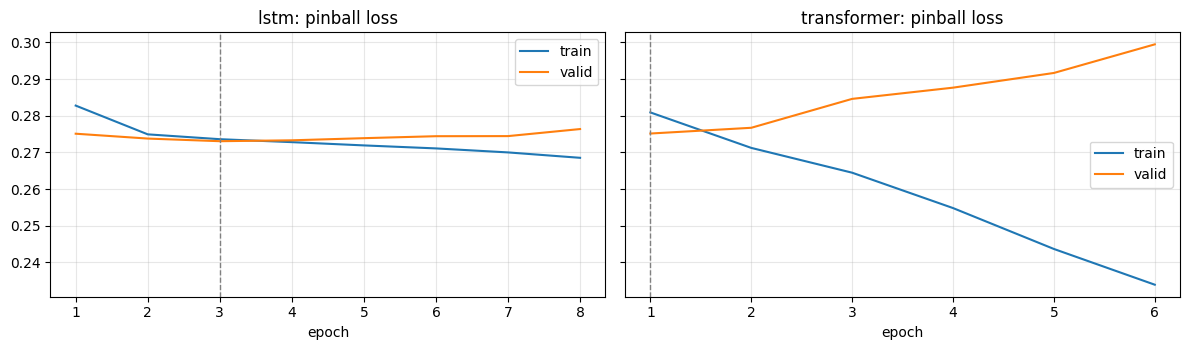

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (name, c) in zip(axes, CURVES.items()):
    ax.plot(c.epoch, c.train, label="train"); ax.plot(c.epoch, c.valid, label="valid")
    ax.axvline(BEST_EPOCH[name], ls="--", c="gray", lw=1); ax.set_title(f"{name}: pinball loss"); ax.set_xlabel("epoch")
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

**คำถามชวนคิด:** train loss ลดลงเรื่อยๆ แต่ valid loss หยุดลดหรือเพิ่มขึ้นหลังไม่กี่ epoch แปลว่าอะไร และทำไม deep learning กับข้อมูลหุ้นถึงเกิดเร็วมาก

<details><summary>เฉลย</summary>

โมเดลเริ่ม overfit: จำ noise ในอดีตแทนที่จะเรียนรู้รูปแบบที่ใช้ได้กับอนาคต ข้อมูลหุ้นมี **signal-to-noise ต่ำมาก** (ผลตอบแทนรายวันเกือบทั้งหมดเป็น noise) และมีตัวอย่างไม่มาก (~20,000 หน้าต่างที่ซ้อนทับกันเกือบทั้งหมด) โมเดลที่มีพารามิเตอร์ 50,000–120,000 ตัวจึงจำ train ได้เร็ว early stopping, dropout และ weight decay คือเครื่องมือกันเรื่องนี้
</details>

### 7.4 เทียบ 4 โมเดลบน valid

In [45]:
def dl_eval(model, mask):
    q = predict_z(model, Xn[mask]) * SC[mask][..., None]          # quantile ของ log return (N, 7, 3)
    y = lab.loc[mask, Y].to_numpy()
    return q, ((y >= q[..., 0]) & (y <= q[..., 2])).mean()

COVER = {}
for name, model in DL.items():
    q, COVER[name] = dl_eval(model, M["valid"])
    VALID_PRED[name] = q[..., 1]
res = pd.DataFrame(sum((score(M["valid"], p, k) for k, p in VALID_PRED.items()), []))
naive_err = res[res.model == "naive"].set_index("h")["%err"]
res["ชนะ naive (%)"] = (1 - res["%err"] / res.h.map(naive_err)) * 100

def n_params(name):
    return sum(p.numel() for p in DL[name].parameters()) if name in DL else (0 if name == "naive" else np.nan)
summary = res.groupby("model", sort=False).agg(**{"%err เฉลี่ย": ("%err", "mean"), "ชนะ naive (%)": ("ชนะ naive (%)", "mean"),
                                                 "ทิศถูก": ("ทิศถูก", "mean")})
summary["coverage 80% (ยังไม่ปรับ)"] = [COVER.get(k, np.nan) for k in summary.index]
summary["parameters"] = [n_params(k) for k in summary.index]
summary["เวลาเทรน (วินาที)"] = [TRAIN_SEC[k] for k in summary.index]
display(summary.round(4))
res.pivot(index="h", columns="model", values="ชนะ naive (%)").round(2)

,%err เฉลี่ย,ชนะ naive (%),ทิศถูก,coverage 80% (ยังไม่ปรับ),parameters,เวลาเทรน (วินาที)
model,,,,,,
naive,2.5112,0.0000,NaN,NaN,0.0,0.0000
hgb,2.5317,-0.6375,0.5467,NaN,NaN,5.4440
lstm,2.4822,1.0536,0.5653,0.7798,58005.0,4.0466
transformer,2.4971,0.4242,0.5406,0.7764,120085.0,5.0073


model,hgb,lstm,naive,transformer
h,,,,
1,0.50,0.28,0.0,-0.73
2,-0.31,0.86,0.0,0.43
3,-0.85,1.05,0.0,-0.10
4,-0.03,1.21,0.0,1.16
5,-0.88,1.15,0.0,0.80
6,-0.61,1.42,0.0,0.53
7,-2.28,1.40,0.0,0.88


**คำถามชวนคิด**

1. LSTM หรือ Transformer ชนะ? ชนะ Gradient Boosting หรือไม่ และชนะ naive หรือไม่
2. ส่วนต่างของ %err ระหว่างโมเดลที่ดีที่สุดกับ naive มีขนาดเท่าไร เทียบกับความซับซ้อนที่เพิ่มขึ้น (พารามิเตอร์ เวลาเทรน GPU ขนาด dependency)
3. coverage ของช่วง 80% ที่โมเดลเรียนรู้เอง ใกล้ 0.80 แค่ไหน

<details><summary>แนวคำตอบ</summary>

1–2. ผลแต่ละรอบต่างกันได้ (ขึ้นกับช่วงเวลาของข้อมูลและ random seed) แต่โดยทั่วไปทุกโมเดลอยู่ในช่วง ±1–2% ของ naive deep learning **ไม่ได้ชนะโมเดลตารางเสมอไป** บนข้อมูลตารางขนาดเล็กที่มี noise สูง (มีงานวิจัยหลายชิ้นพบว่า gradient boosting ชนะ neural network บนข้อมูลตาราง) สิ่งที่ deep learning ให้ในโจทย์นี้ชัดๆ คือ **โมเดลเดียวทำนายครบ 7 วันพร้อมช่วงคาดการณ์** และรับ input เป็นลำดับเวลาโดยไม่ต้องคิด feature ย้อนหลังเอง ซึ่งต้องชั่งกับต้นทุนการเทรน การ debug และการ deploy
3. pinball loss ทำให้ quantile ใกล้เป้าบน **ข้อมูลที่เทรน** แต่บนข้อมูลใหม่มักคลาดเคลื่อน (มักแคบเกินไปเมื่อ overfit) จึงต้อง calibrate ในส่วน 8
</details>

## ส่วน 8: เลือกโมเดล, conformal calibration และทดสอบบน test (ครั้งเดียว)

1. **เลือก** โมเดล deep learning ที่ %err เฉลี่ยบน valid ต่ำที่สุด (Gradient Boosting เป็นเส้นอ้างอิง ไม่ได้ deploy ใน Lab นี้ ถ้ามันชนะ ให้บันทึกไว้และตอบในคำถามท้าย Lab)
2. **Conformalized Quantile Regression (CQR)** (Romano et al., NeurIPS 2019): บน valid คำนวณ `E = max(q0.1 − z, z − q0.9)` (ค่าจริงหลุดขอบไปเท่าไร ติดลบถ้าอยู่ข้างใน) แล้วหา quantile 80% ของ E ต่อ horizon ช่วงใหม่คือ `[q0.1 − E80, q0.9 + E80]` ถ้าช่วงเดิมแคบไป E80 > 0 จะขยาย ถ้ากว้างไป E80 < 0 จะหด
3. **ทดสอบ:** เทรนใหม่ด้วย train + valid เท่ากับ `best_epoch` แล้ววัดบน test ครั้งเดียว

In [46]:
dl_err = summary.loc[list(DL), "%err เฉลี่ย"]
BEST = dl_err.idxmin()
print("%err เฉลี่ยบน valid:", summary["%err เฉลี่ย"].round(4).to_dict(), "→ deploy", BEST)
if summary.loc[BEST, "%err เฉลี่ย"] >= summary.loc["naive", "%err เฉลี่ย"]:
    print("⚠️ deep learning ไม่ชนะ naive บน valid — บันทึกไว้ใน model card และคิดต่อในคำถามท้าย Lab")
if summary.loc[BEST, "%err เฉลี่ย"] >= summary.loc["hgb", "%err เฉลี่ย"]:
    print("⚠️ Gradient Boosting ดีกว่าหรือเท่ากับ deep learning บน valid")

zq = predict_z(DL[BEST], Xn[M["valid"]])
zv = Z[M["valid"]]
E = np.maximum(zq[..., 0] - zv, zv - zq[..., 2])          # > 0 = ค่าจริงหลุดช่วงไปเท่าไร, < 0 = อยู่ข้างใน
nv = len(E)
CQR = {str(h): float(np.quantile(E[:, j], min(1.0, math.ceil((nv + 1) * LEVEL) / nv))) for j, h in enumerate(sp.HORIZONS)}
print("ค่าปรับ CQR (หน่วย z):", {k: round(v, 3) for k, v in CQR.items()})

%err เฉลี่ยบน valid: {'naive': 2.5112, 'hgb': 2.5317, 'lstm': 2.4822, 'transformer': 2.4971} → deploy lstm
ค่าปรับ CQR (หน่วย z): {'1': 0.005, '2': 0.046, '3': 0.054, '4': 0.093, '5': 0.083, '6': 0.073, '7': 0.07}


In [47]:
t0 = time.time()
dl_tv, _, _ = train(ARCH[BEST], M["trval"], epochs=BEST_EPOCH[BEST], verbose=False)
hgb_tv = fit_hgb(M["trval"])
print(f"เทรน {BEST} + hgb ด้วย train+valid: {time.time() - t0:.0f} วินาที")

mt = M["test"]
y_te = lab.loc[mt, Y].to_numpy()
q_te = predict_z(dl_tv, Xn[mt])
sc_te = SC[mt]
adj = np.array([CQR[str(h)] for h in sp.HORIZONS])
raw_in = (y_te >= q_te[..., 0] * sc_te) & (y_te <= q_te[..., 2] * sc_te)
cqr_in = (y_te >= (q_te[..., 0] - adj) * sc_te) & (y_te <= (q_te[..., 2] + adj) * sc_te)
p_hgb, p_dl = hgb_logret(hgb_tv, mt), q_te[..., 1] * sc_te

rows = []
for j, h in enumerate(sp.HORIZONS):
    yt = y_te[:, j]
    rows.append({"h": h, "naive %err": price_err(yt, 0 * yt), "hgb %err": price_err(yt, p_hgb[:, j]),
                 f"{BEST} %err": price_err(yt, p_dl[:, j]), "ทิศถูก": np.mean(np.sign(p_dl[:, j]) == np.sign(yt)),
                 "coverage ก่อนปรับ": raw_in[:, j].mean(), "coverage 80%": cqr_in[:, j].mean()})
test_table = pd.DataFrame(rows).set_index("h")
test_table["ชนะ naive (%)"] = (1 - test_table[f"{BEST} %err"] / test_table["naive %err"]) * 100
test_table.round(3)

เทรน lstm + hgb ด้วย train+valid: 7 วินาที


,naive %err,hgb %err,lstm %err,ทิศถูก,coverage ก่อนปรับ,coverage 80%,ชนะ naive (%)
h,,,,,,,
1,1.304,1.309,1.309,0.518,0.776,0.777,-0.340
2,1.905,1.913,1.910,0.528,0.769,0.782,-0.241
3,2.339,2.366,2.347,0.538,0.762,0.779,-0.308
4,2.714,2.746,2.726,0.546,0.762,0.798,-0.447
5,3.037,3.084,3.063,0.544,0.764,0.799,-0.865
6,3.335,3.377,3.361,0.559,0.773,0.796,-0.770
7,3.596,3.653,3.625,0.558,0.771,0.801,-0.827


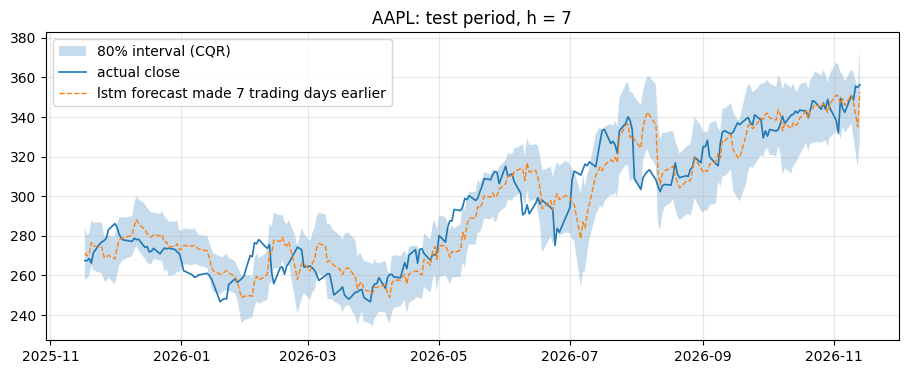

In [48]:
# ภาพ test ของหุ้น 1 ตัว: ราคาจริง vs คำทำนายล่วงหน้า 7 วันทำการ พร้อมช่วง 80% (หลังปรับ CQR)
TK, j = "AAPL", 6
sel = (lab.Ticker[mt] == TK).to_numpy()
t = lab.loc[mt].loc[sel]
c = t["Close"].to_numpy()
x = t["Date"] + pd.offsets.BDay(7)                     # วาดที่ "วันเป้าหมาย" (ประมาณ)
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(x, c * np.exp((q_te[sel, j, 0] - adj[j]) * sc_te[sel, j]), c * np.exp((q_te[sel, j, 2] + adj[j]) * sc_te[sel, j]),
                alpha=.25, label="80% interval (CQR)")
ax.plot(x, c * np.exp(y_te[sel, j]), lw=1.2, label="actual close")
ax.plot(x, c * np.exp(p_dl[sel, j]), lw=1, ls="--", label=f"{BEST} forecast made 7 trading days earlier")
ax.set_title(f"{TK}: test period, h = 7"); ax.legend(); ax.grid(alpha=.3); plt.show()

**คำถามชวนคิด**

1. เส้นคำทำนายดูเหมือน "เลื่อน" ตามเส้นราคาจริงไปทางขวาหรือไม่ บอกอะไรเกี่ยวกับโมเดล
2. coverage ก่อนปรับกับหลังปรับ CQR ต่างกันแค่ไหน ถ้า coverage ต่ำกว่า 80% มาก ผู้ใช้ที่เชื่อช่วงนี้จะเจออะไร
3. ทำไมต้องเลือกโมเดลและหาค่า CQR บน valid ไม่ใช่บน test

<details><summary>เฉลย</summary>

1. ใช่ เส้นทำนายเกือบเท่ากับราคาเมื่อ 7 วันก่อน (โมเดลใกล้เคียง naive) กราฟแบบนี้ทำให้คนทั่วไปคิดว่า "ทำนายแม่นมาก" ทั้งที่แค่ลอกราคาล่าสุด จึงต้องดูตัวเลขเทียบ naive เสมอ
2. ผู้ใช้จะประเมินความเสี่ยงต่ำเกินจริง CQR รับประกัน coverage เฉลี่ยเมื่อข้อมูลใหม่ "แลกเปลี่ยนกันได้" กับชุดที่ใช้ปรับ ซึ่งอนุกรมเวลาการเงินไม่เป็นจริงเสมอ (ช่วงตลาดผันผวนกว่าช่วง valid coverage จะตก) จึงต้อง **monitor coverage หลัง deploy** (Lab 3.2 คำนวณให้ทุกวัน)
3. ถ้าใช้ test ตัดสินใจ test จะกลายเป็นส่วนหนึ่งของการเทรน ตัวเลขบน test จะดีเกินจริง และไม่มีข้อมูลที่เป็นกลางเหลือไว้ประเมิน
</details>

## ส่วน 9: เทรนครั้งสุดท้าย, export ONNX และทำนายแบบระบบจริง

1. เทรน `BEST` ด้วย **ทุกตัวอย่างที่มี target** เท่ากับ `best_epoch` (ตัวเลขใน model card จึงเป็น "ค่าประมาณ" จาก test ของโมเดลที่เทรนถึงก่อนช่วง test) ใช้ scaler และค่า CQR ชุดเดิม
2. **Export เป็น ONNX** (Open Neural Network Exchange): ไฟล์เดียวเก็บทั้งโครงสร้างและน้ำหนัก รันด้วย `onnxruntime` ได้โดยไม่ต้องมี PyTorch

| | PyTorch | onnxruntime |
|---|---|---|
| ขนาดที่ต้องติดตั้งบนเครื่อง deploy | ~700 MB (CPU) ถึงหลาย GB (CUDA) | ~15–20 MB |
| ต้องมีโค้ด class ของโมเดล | ใช่ | ไม่ (โครงสร้างอยู่ในไฟล์) |
| ใช้ทำอะไร | เทรน | ทำนาย (inference) อย่างเดียว |

3. **ตรวจว่า ONNX ให้ผลเท่ากับ PyTorch** แล้วทำนายด้วย `sp.forecast()` **ผ่าน ONNX** ซึ่งเป็นเส้นทางเดียวกับที่ GitHub Actions จะใช้ทุกเช้า

In [49]:
t0 = time.time()
final, _, _ = train(ARCH[BEST], M["all"], epochs=BEST_EPOCH[BEST], verbose=False)
final = final.cpu().eval()
print(f"เทรน {BEST} ด้วยทุกตัวอย่าง ({M['all'].sum()} ตัวอย่าง, {BEST_EPOCH[BEST]} epoch): {time.time() - t0:.0f} วินาที")

ONNX_PATH = "forecaster.onnx"
example = (torch.from_numpy(Xn[:8]),)
try:   # exporter แบบใหม่ (torch.export) — ค่าเริ่มต้นตั้งแต่ PyTorch 2.9
    torch.onnx.export(final, example, ONNX_PATH, input_names=["x"], output_names=["q"], dynamo=True,
                      dynamic_shapes=({0: torch.export.Dim("batch", min=1, max=4096)},), external_data=False)
except Exception as e:   # สำรอง: exporter แบบเดิม (TorchScript)
    print("dynamo export ไม่สำเร็จ ใช้ exporter แบบเดิม:", type(e).__name__)
    torch.onnx.export(final, example, ONNX_PATH, input_names=["x"], output_names=["q"], dynamo=False,
                      dynamic_axes={"x": {0: "batch"}, "q": {0: "batch"}})
onnx.checker.check_model(ONNX_PATH)
print(f"{ONNX_PATH}: {os.path.getsize(ONNX_PATH) / 1024:.0f} KB")

เทรน lstm ด้วยทุกตัวอย่าง (28990 ตัวอย่าง, 3 epoch): 2 วินาที
[torch.onnx] Obtain model graph for `LSTMForecaster([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `LSTMForecaster([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
forecaster.onnx: 294 KB


In [50]:
# ONNX ต้องให้ผลเท่ากับ PyTorch (ต่างได้แค่ระดับเศษทศนิยมของ float32)
predict_onnx = sp.onnx_predictor(ONNX_PATH)
check = Xn[np.random.default_rng(0).choice(len(Xn), 2000, replace=False)]
with torch.no_grad():
    a = final(torch.from_numpy(check)).numpy()
b = predict_onnx(check)
print(f"PyTorch vs ONNX บน 2,000 ตัวอย่าง: ต่างกันมากที่สุด {np.abs(a - b).max():.2e}")
assert np.abs(a - b).max() < 1e-4

x10 = Xn[:10]
t0 = time.perf_counter(); [predict_onnx(x10) for _ in range(50)]
print(f"onnxruntime (CPU, 1 thread): {(time.perf_counter() - t0) / 50 * 1000:.1f} ms ต่อการทำนาย 10 หุ้น")

PyTorch vs ONNX บน 2,000 ตัวอย่าง: ต่างกันมากที่สุด 7.15e-07
onnxruntime (CPU, 1 thread): 1.2 ms ต่อการทำนาย 10 หุ้น


In [51]:
META_INTERVAL = {"level": LEVEL, "quantiles": sp.QUANTILES, "cqr": CQR}
Xl, il = sp.latest_windows(feat, TICKERS)
AS_OF = il.Date.iloc[0]
target_dates = sp.next_sessions(AS_OF, len(sp.HORIZONS))
fc = sp.forecast(predict_onnx, {"scaler": SCALER, "interval": META_INTERVAL}, Xl, il)
fc["target_date"] = fc.h.map(lambda h: target_dates[h - 1].date())
print("as_of (ราคาปิดล่าสุด):", AS_OF.date(), "| วันเป้าหมาย:", [str(d.date()) for d in target_dates])
fc.assign(chg_pct=(fc.pred_close / fc.last_close - 1) * 100).pivot(
    index="ticker", columns="h", values="chg_pct").round(2).add_prefix("h").rename_axis("% เปลี่ยนจากราคาปิดล่าสุด", axis=1)

as_of (ราคาปิดล่าสุด): 2026-11-13 | วันเป้าหมาย: ['2026-11-16', '2026-11-17', '2026-11-18', '2026-11-19', '2026-11-20', '2026-11-23', '2026-11-24']


% เปลี่ยนจากราคาปิดล่าสุด,h1,h2,h3,h4,h5,h6,h7
ticker,,,,,,,
AAPL,0.04,0.13,0.19,0.22,0.27,0.31,0.36
AMZN,0.06,0.24,0.35,0.39,0.49,0.55,0.62
GOOGL,0.05,0.07,0.29,0.12,0.43,0.34,0.54
JNJ,0.07,0.24,0.24,0.42,0.40,0.47,0.50
JPM,0.04,0.14,0.17,0.25,0.25,0.30,0.37
KO,0.04,0.14,0.18,0.23,0.26,0.29,0.33
MSFT,0.05,0.18,0.27,0.31,0.38,0.46,0.52
NVDA,0.08,0.27,0.12,0.62,0.20,0.48,0.64
WMT,0.04,0.17,0.19,0.29,0.28,0.34,0.38


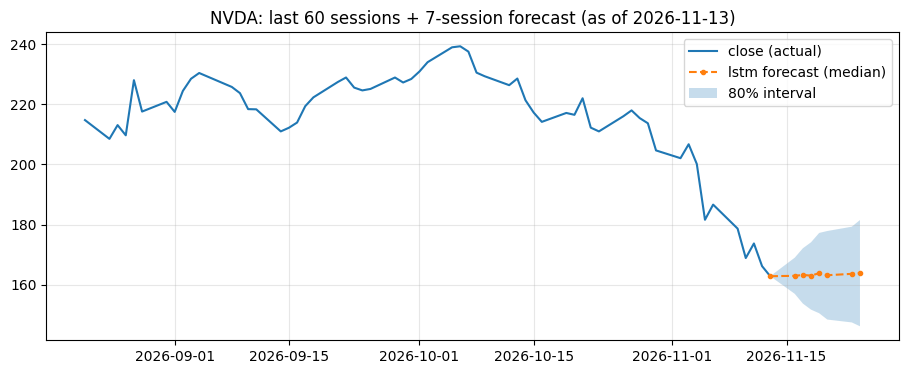

In [52]:
TK = "NVDA"
hist = prices[prices.Ticker == TK].tail(60)
f = fc[fc.ticker == TK]
xd = [hist.Date.iloc[-1], *[pd.Timestamp(d) for d in f.target_date]]
c0 = hist.Close.iloc[-1]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist.Date, hist.Close, label="close (actual)")
ax.plot(xd, [c0, *f.pred_close], "o--", ms=3, label=f"{BEST} forecast (median)")
ax.fill_between(xd, [c0, *f.lo], [c0, *f.hi], alpha=.25, label="80% interval")
ax.set_title(f"{TK}: last 60 sessions + 7-session forecast (as of {AS_OF.date()})"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## ส่วน 10: Export artifacts สำหรับ Lab 3.2

| ไฟล์ใน zip | ใช้ทำอะไรใน Lab 3.2 |
|---|---|
| `stock_pipeline.py` | โค้ดเตรียมข้อมูล หน้าต่าง normalize และ `forecast()` **ไฟล์เดียวกับที่ใช้เทรน** |
| `models/forecaster.onnx` | โมเดล deep learning (โครงสร้าง + น้ำหนัก) |
| `models/model_metadata.json` | รุ่นโมเดล, สถาปัตยกรรม, รายชื่อหุ้น, `SEQ_FEATURES`, **mean/std ของ scaler**, ค่า CQR, ผล valid/test, เวอร์ชัน library |
| `samples/prices_sample.csv` | ราคา 120 วันล่าสุด (ข้อมูลดิบแบบเดียวกับที่ดาวน์โหลด) |
| `samples/expected_forecast.json` | คำทำนายที่ Colab ได้จาก `prices_sample.csv` **ผ่าน ONNX** ใช้ตรวจว่าเครื่อง deploy ให้ผลเท่ากัน |
| `requirements.txt` | library ฝั่ง deploy **ตรึงเวอร์ชันให้ตรงกับ Colab** (ไม่มี PyTorch และ scikit-learn) |
| `MODEL_CARD.md` | สรุปโมเดลสำหรับคนอ่าน |

In [53]:
OUT = "export_stock"
shutil.rmtree(OUT, ignore_errors=True)
for d in ("models", "samples"):
    os.makedirs(f"{OUT}/{d}", exist_ok=True)
shutil.copy("stock_pipeline.py", f"{OUT}/stock_pipeline.py")
shutil.copy(ONNX_PATH, f"{OUT}/models/forecaster.onnx")

def table(df):
    return {str(k): {c: (None if pd.isna(v) else round(float(v), 4)) for c, v in r.items()} for k, r in df.iterrows()}

ARCH_DESC = {"lstm": "LSTM 2 layers, hidden 64, dropout 0.2 → quantile head",
             "transformer": "PatchTST-style: patch 10 / stride 5, d_model 64, 4 heads, 2 blocks → quantile head"}
MODEL_VERSION = f"stock-{BEST}-{sp.FEATURE_VERSION}-{AS_OF:%Y%m%d}"
meta = {
    "model_version": MODEL_VERSION,
    "feature_version": sp.FEATURE_VERSION,
    "algorithm": BEST,
    "architecture": ARCH_DESC[BEST],
    "parameters": int(sum(p.numel() for p in final.parameters())),
    "training": {"loss": "pinball (quantile) loss", "optimizer": "AdamW", "lr": LR, "batch": BATCH,
                 "epochs": BEST_EPOCH[BEST], "early_stopping_patience": PATIENCE, "seed": SEED, "device": DEV},
    "input": {"name": "x", "shape": ["batch", sp.SEQ_LEN, Fdim], "seq_len": sp.SEQ_LEN, "features": sp.SEQ_FEATURES},
    "output": {"name": "q", "shape": ["batch", len(sp.HORIZONS), len(sp.QUANTILES)],
               "meaning": "quantiles of z_h = log(Close[t+h]/Close[t]) / (vol_20 * sqrt(h))"},
    "scaler": SCALER,
    "tickers": TICKERS, "market": sp.MARKET, "horizons": sp.HORIZONS,
    "data": {"source": "Yahoo Finance via yfinance (auto_adjust=False, Close split-adjusted only)",
             "start": str(prices.Date.min().date()), "last_close_date": str(AS_OF.date()),
             "trained_until": str(lab.Date.max().date())},
    "splits": {k: {"start": str(lab.Date[M[k]].min().date()), "end": str(lab.Date[M[k]].max().date()),
                   "samples": int(M[k].sum())} for k in ("train", "valid", "test")} | {"purge_days": PURGE},
    "metrics": {"valid_summary": table(summary.drop(columns=["parameters"])), "test": table(test_table)},
    "interval": META_INTERVAL | {"test_coverage": {str(h): round(float(v), 4) for h, v in test_table["coverage 80%"].items()}},
    "min_history_days": sp.MIN_HISTORY,
    "versions": {"python": sys.version.split()[0], "torch": torch.__version__, "onnx": onnx.__version__,
                 "onnxruntime": onnxruntime.__version__, "pandas": pd.__version__, "numpy": np.__version__,
                 "yfinance": yf.__version__},
    "exported_at": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "disclaimer": "Educational use only. Not investment advice.",
}
json.dump(meta, open(f"{OUT}/models/model_metadata.json", "w"), indent=2, ensure_ascii=False)

# ข้อมูลตัวอย่าง + คำตอบที่ถูกต้อง: ผ่านเส้นทางเดียวกับระบบจริงทุกขั้น (csv → feature → หน้าต่าง → ONNX → ราคา)
sample = prices[prices.Date >= np.sort(prices.Date.unique())[-SAMPLE_DAYS]]
sample.to_csv(f"{OUT}/samples/prices_sample.csv", index=False)
sample_back = pd.read_csv(f"{OUT}/samples/prices_sample.csv", parse_dates=["Date"])
Xs, is_ = sp.latest_windows(sp.build_features(sample_back), TICKERS)
exp_fc = sp.forecast(sp.onnx_predictor(f"{OUT}/models/forecaster.onnx"), meta, Xs, is_)
assert np.allclose(exp_fc.pred_close, fc.pred_close, rtol=1e-6), "ข้อมูล 120 วันให้ผลไม่เท่าข้อมูลทั้งหมด!"
json.dump({"model_version": MODEL_VERSION, "as_of": str(AS_OF.date()), "rows": exp_fc.to_dict(orient="records")},
          open(f"{OUT}/samples/expected_forecast.json", "w"), indent=1)

pins = {"onnxruntime": onnxruntime.__version__, "pandas": pd.__version__, "numpy": np.__version__,
        "yfinance": yf.__version__, "pandas_market_calendars": mcal.__version__}
open(f"{OUT}/requirements.txt", "w").write("".join(f"{k}=={v}\n" for k, v in pins.items()))

tt = test_table.round(3)
card = f'''# Model card: {MODEL_VERSION}

**ใช้เพื่อการศึกษาเท่านั้น ไม่ใช่คำแนะนำการลงทุน**

- **ทำนายอะไร:** ราคาปิดของ {len(TICKERS)} หุ้นใน S&P 500 ล่วงหน้า 1–7 วันทำการ ({", ".join(TICKERS)}) พร้อมช่วงคาดการณ์ {LEVEL:.0%}
- **โมเดล:** `{BEST}` — {ARCH_DESC[BEST]} ({meta["parameters"]:,} parameters), input หน้าต่าง {sp.SEQ_LEN} วัน × {Fdim} ช่อง, output 7 horizon × quantile {sp.QUANTILES}, ช่วงคาดการณ์ปรับด้วย conformalized quantile regression บนชุด valid
- **เทรน:** pinball loss, AdamW, {BEST_EPOCH[BEST]} epoch (จาก early stopping), ข้อมูลถึง {meta["data"]["trained_until"]}; รันจริงด้วย ONNX (`onnxruntime`)
- **ข้อมูล:** Yahoo Finance ({meta["data"]["start"]} → {meta["data"]["last_close_date"]}), Close ปรับเฉพาะ split
- **ผลบน test** ({meta["splits"]["test"]["start"]} → {meta["splits"]["test"]["end"]}, โมเดลที่เทรนถึงก่อนช่วง test):

| h | naive %err | hgb %err | {BEST} %err | ชนะ naive (%) | coverage ก่อนปรับ | coverage 80% |
|---|---|---|---|---|---|---|
''' + "".join(f"| {h} | {r['naive %err']} | {r['hgb %err']} | {r[f'{BEST} %err']} | {r['ชนะ naive (%)']} | {r['coverage ก่อนปรับ']} | {r['coverage 80%']} |\n"
              for h, r in tt.iterrows()) + '''
- **ข้อจำกัด:** ราคาหุ้นใกล้ random walk โมเดลชนะ naive น้อยมากหรือไม่ชนะ และอาจไม่ชนะ Gradient Boosting; ผลขึ้นกับ random seed; ช่วงคาดการณ์สมมติว่าอนาคตคล้ายช่วง valid (ไม่รู้ล่วงหน้าเรื่องประกาศงบ ข่าว หรือวิกฤต); ไม่รู้จัก split/ปันผลในอนาคต
- **ต้อง monitor:** %err เทียบ naive และ coverage จริงหลัง deploy, ความสดของข้อมูล, ความล่าช้าของงานตั้งเวลา
'''
open(f"{OUT}/MODEL_CARD.md", "w", encoding="utf-8").write(card)

shutil.make_archive("bd532_stock_artifacts", "zip", OUT)
print(open(f"{OUT}/requirements.txt").read())
print("model_version:", MODEL_VERSION)
print("✅ สร้าง bd532_stock_artifacts.zip แล้ว:", sorted(os.path.relpath(os.path.join(r, f), OUT)
                                                     for r, _, fs in os.walk(OUT) for f in fs))

onnxruntime==1.32.0
pandas==3.1.1
numpy==2.4.6
yfinance==1.8.0
pandas_market_calendars==5.6.1

model_version: stock-lstm-v2-seq-20261113
✅ สร้าง bd532_stock_artifacts.zip แล้ว: ['MODEL_CARD.md', 'models/forecaster.onnx', 'models/model_metadata.json', 'requirements.txt', 'samples/expected_forecast.json', 'samples/prices_sample.csv', 'stock_pipeline.py']


In [54]:
from google.colab import files
files.download("bd532_stock_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

> ✅ **Checkpoint (ก่อนไป Lab 3.2)**
> - [ ] ตารางส่วน 4 (สุ่ม vs ตามเวลา) และเหตุผลที่แบบสุ่มดีเกินจริง
> - [ ] learning curve ของ LSTM และ Transformer พร้อม best epoch
> - [ ] ตาราง valid ของ 4 โมเดล: deep learning ชนะ Gradient Boosting และ naive หรือไม่ แลกกับความซับซ้อนเท่าไร
> - [ ] ตาราง test: %err ของ naive / hgb / โมเดลที่เลือก ที่ h = 1 และ h = 7 และ coverage ก่อน/หลังปรับ CQR
> - [ ] ผลต่าง PyTorch vs ONNX และมีไฟล์ `bd532_stock_artifacts.zip` บนเครื่อง
> - [ ] ดาวน์โหลดโน้ตบุ๊กนี้ที่รันแล้ว (**File → Download → Download .ipynb**)

➡️ **ไปทำ Lab 3.2 ในคู่มือ `BD532-Lab3-Stock-Forecast.md`**